In [1]:
import numpy as np # linear algebra
dataset="/kaggle/input/synthetic-speech-commands-dataset/augmented_dataset/augmented_dataset"


In [2]:
import os
import pandas as pd


# Lister uniquement les dossiers dans dataset
subdirs = [d for d in os.listdir(dataset) if os.path.isdir(os.path.join(dataset, d))]

# Créer un DataFrame avec le chemin relatif et le nom du dossier
df = pd.DataFrame({'Path': [os.path.join(dataset, d) for d in subdirs], 'Labels': subdirs})


In [3]:

# Fonction pour compter le nombre de fichiers dans chaque sous-dossier
def count_samples(path):
    return [len(os.listdir(os.path.join(path, d))) for d in subdirs]

# Création du DataFrame
df['Number Of Samples'] = count_samples(dataset) 

In [4]:
df.head()

,Path,Labels,Number Of Samples
0,/kaggle/input/synthetic-speech-commands-datase...,no,957
1,/kaggle/input/synthetic-speech-commands-datase...,two,902
2,/kaggle/input/synthetic-speech-commands-datase...,four,2400
3,/kaggle/input/synthetic-speech-commands-datase...,five,1092
4,/kaggle/input/synthetic-speech-commands-datase...,nine,1144


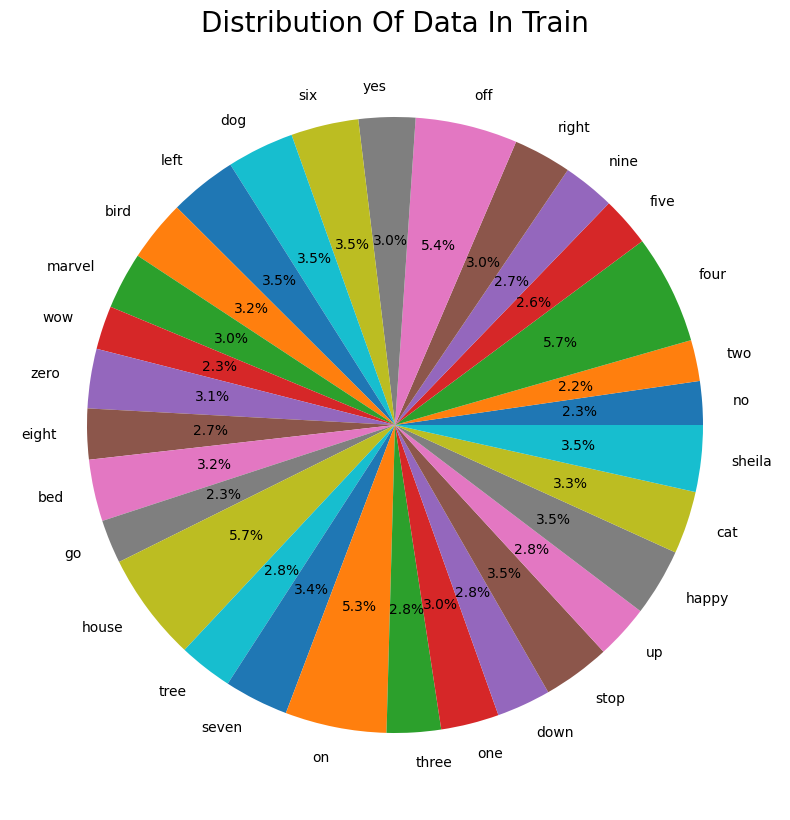

In [5]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,10))
plt.pie(x=df['Number Of Samples'],labels=os.listdir(dataset),autopct ='%1.1f%%',data=df)
plt.title('Distribution Of Data In Train',fontsize=20)
plt.show()

In [6]:
import IPython.display as ipd
#bed Audio
ipd.Audio('/kaggle/input/synthetic-speech-commands-dataset/augmented_dataset/augmented_dataset/bed/1014.wav')



In [7]:
#cat Audio
ipd.Audio('/kaggle/input/synthetic-speech-commands-dataset/augmented_dataset/augmented_dataset/cat/1009.wav')

In [8]:
#yes Audio
ipd.Audio('/kaggle/input/synthetic-speech-commands-dataset/augmented_dataset/augmented_dataset/yes/1014.wav')

In [9]:
import os
import librosa as lr  

def load(path):
    """
    Charge les fichiers audio depuis un répertoire donné et retourne les données, les étiquettes et le taux d'échantillonnage.

    Args:
    path (str): Le chemin vers le répertoire contenant les sous-dossiers (chaque sous-dossier est une classe).
    
    Returns:
    data (list): Liste contenant les données audio pour chaque fichier.
    label (list): Liste des étiquettes (nom des sous-dossiers).
    sample (list): Liste des taux d'échantillonnage des fichiers audio.
    """
    data = []
    label = []
    sample = []
    
    # Parcours des sous-dossiers (classes)
    for file in os.listdir(path):
        path_ = os.path.join(path, file)  # Crée le chemin du sous-dossier (classe)
        
        # Si c'est un dossier, on continue
        if os.path.isdir(path_):
            for fil in os.listdir(path_):  # Parcours des fichiers audio dans le sous-dossier
                file_path = os.path.join(path_, fil)  # Crée le chemin complet du fichier
                
                # Charger le fichier audio
                data_contain, sample_rate = lr.load(file_path, sr=16000)
                
                # Ajouter les données dans les listes appropriées
                data.append(data_contain)
                sample.append(sample_rate)
                label.append(file)  # L'étiquette est le nom du sous-dossier (classe)
    
    return data, label, sample


In [10]:
data,label,sample=load(dataset)

In [11]:
#audio en vecteur
data[0]

array([-9.1552734e-05, -9.1552734e-05,  0.0000000e+00, ...,
        1.2207031e-04,  1.5258789e-04,  9.1552734e-05], dtype=float32)

In [12]:
#label
label[950:960]

['no', 'no', 'no', 'no', 'no', 'no', 'no', 'two', 'two', 'two']

In [13]:
# nombre d'échantillons par seconde.
sample[0]

16000

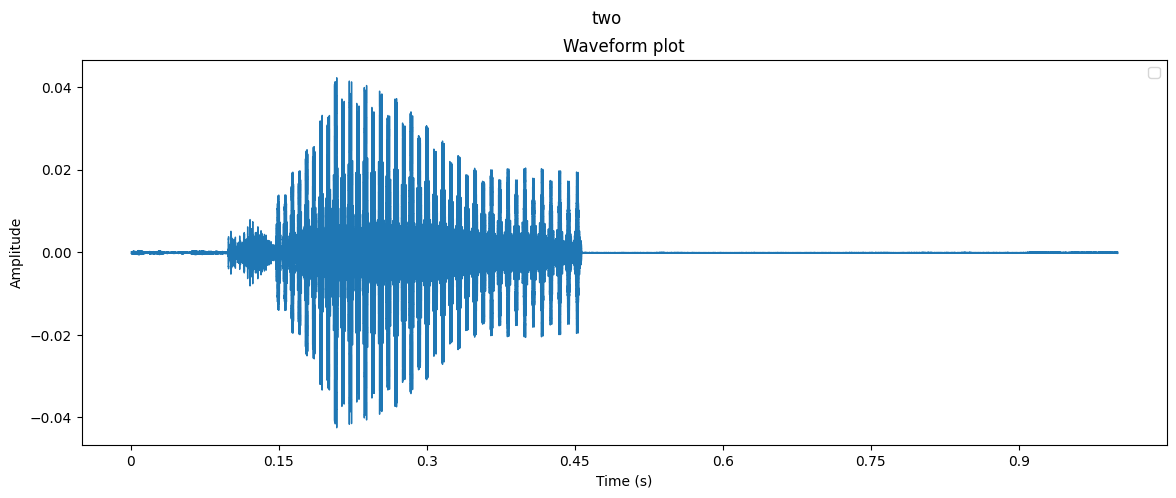

In [14]:
#waveform
def waveform(data,sr,label):
    plt.figure(figsize=(14, 5))
    lr.display.waveshow(data, sr=sr)
    plt.suptitle(label)
    plt.title('Waveform plot')
    plt.xlabel('Time (s)')
    plt.ylabel('Amplitude')
#waveform data[0]
waveform(data[1000],sample[1000],label[1000])
plt.legend()

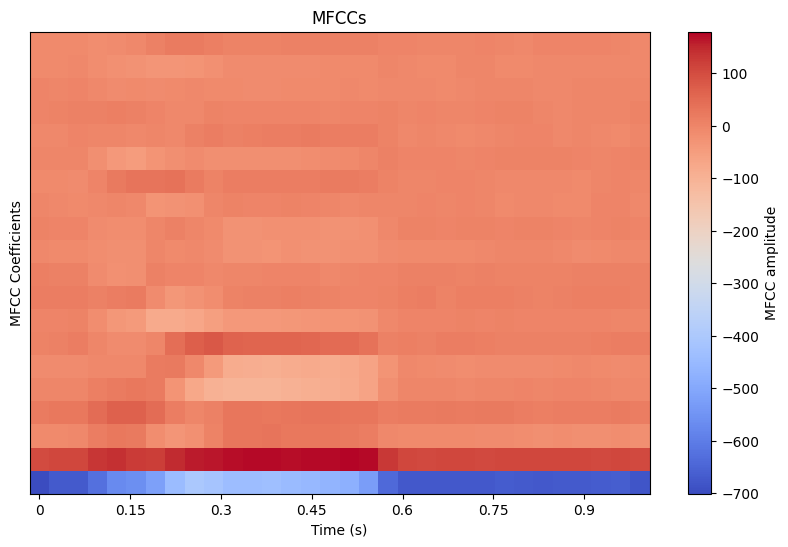

In [15]:
import numpy as np
import scipy.signal
import scipy.fftpack
import librosa

def mfcc(data, sr):
    mfccs = lr.feature.mfcc(y=data, sr=sr)
    return np.mean(mfccs), mfccs

# Exemple d'utilisation
mfccs_mean, mfccs = mfcc(data[0], sample[0])
# Affichage des MFCC
plt.figure(figsize=(10, 6))
librosa.display.specshow(mfccs, x_axis='time', sr=16000, cmap='coolwarm')
plt.colorbar(label='MFCC amplitude')
plt.title('MFCCs')
plt.xlabel('Time (s)')
plt.ylabel('MFCC Coefficients')
plt.show()

In [16]:
#spectrogram
def spectrogram_mel(data, sr):
    mel_spec = lr.feature.melspectrogram(y=data, sr=sr)
    return np.mean(mel_spec), mel_spec


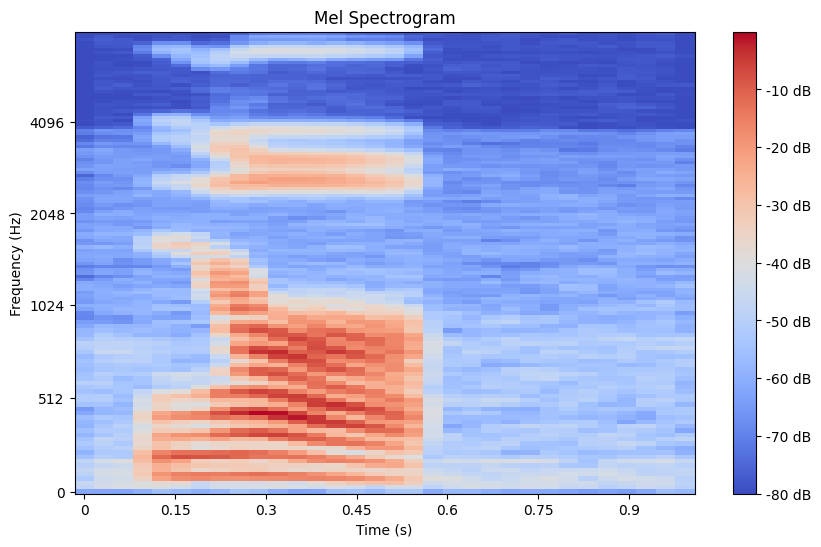

In [17]:
# Calculer le Mel-spectrogramme
mel_mean, mel_spec = spectrogram_mel(data[0], sample[0])

# Convertir l'amplitude en dB pour une meilleure visualisation
mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)

# Afficher le Mel-spectrogramme
plt.figure(figsize=(10, 6))
librosa.display.specshow(mel_spec_db, x_axis='time', y_axis='mel', sr=sample[0], cmap='coolwarm')
plt.colorbar(format='%+2.0f dB')
plt.title('Mel Spectrogram')
plt.xlabel('Time (s)')
plt.ylabel('Frequency (Hz)')
plt.show()

In [18]:
import librosa

def zero_crossing(data, sr):
    # Calculer le taux de passage par zéro
    zcr = librosa.feature.zero_crossing_rate(data)
    
    # Calculer la moyenne du taux de passage par zéro
    avg_zcr = sum(zcr[0])/len(zcr[0])
    print("Moyenne du taux de passage par zéro:", avg_zcr)
    
    # Retourner les valeurs du taux de passage par zéro
    return zcr


Moyenne du taux de passage par zéro: 0.0925750732421875


Text(0.5, 0.98, 'no')

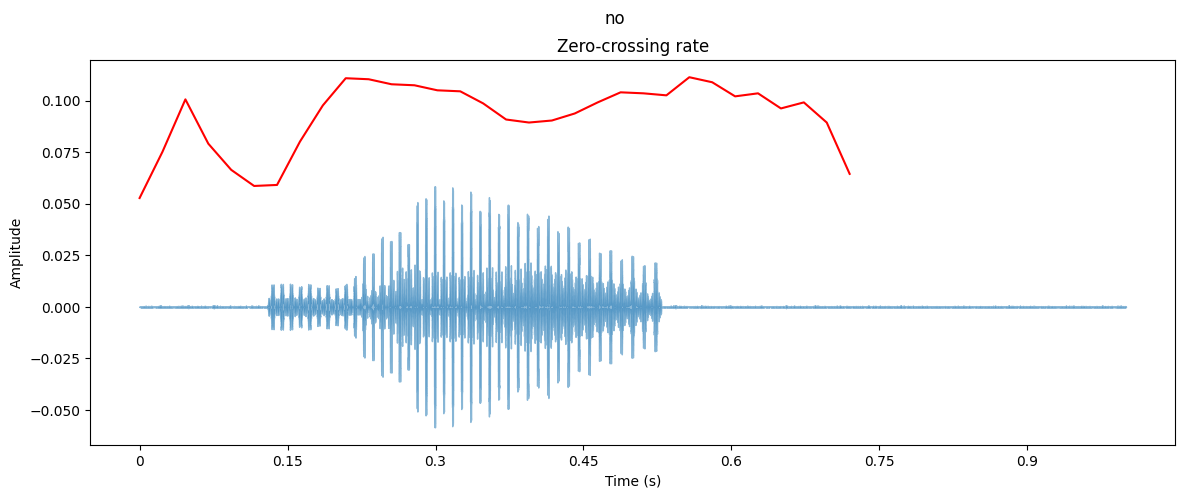

In [19]:
zcr=zero_crossing(data[0],sample[0])
time = lr.times_like(zcr)
# Create waveform plot
plt.figure(figsize=(14, 5))
lr.display.waveshow(data[0], sr=sample[0], alpha=0.5)
plt.plot(time, zcr[0], color='r')
plt.title('Zero-crossing rate')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.suptitle(label[0])

In [20]:
i=0
lbl={}
for l in df['Labels']:
    lbl[l]=i
    i+=1

In [21]:
lbl

{'no': 0,
 'two': 1,
 'four': 2,
 'five': 3,
 'nine': 4,
 'right': 5,
 'off': 6,
 'yes': 7,
 'six': 8,
 'dog': 9,
 'left': 10,
 'bird': 11,
 'marvel': 12,
 'wow': 13,
 'zero': 14,
 'eight': 15,
 'bed': 16,
 'go': 17,
 'house': 18,
 'tree': 19,
 'seven': 20,
 'on': 21,
 'three': 22,
 'one': 23,
 'down': 24,
 'stop': 25,
 'up': 26,
 'happy': 27,
 'cat': 28,
 'sheila': 29}

In [22]:
for i in range(len(label)):
    label[i]=lbl[label[i]]

In [23]:
label[:10]

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

**split data**

In [24]:
from sklearn.model_selection import train_test_split
data=np.array(data).reshape(-1,16000,1)
label=np.array(label)


In [25]:
label

array([ 0,  0,  0, ..., 29, 29, 29])

In [26]:
X_train, X_test, y_train, y_test = train_test_split(data, label, test_size=0.1, random_state=44, shuffle =True)
print('X_train shape is ' , X_train.shape)
print('X_test shape is ' , X_test.shape)
print('y_train shape is ' , y_train.shape)
print('y_test shape is ' , y_test.shape)

X_train shape is  (37664, 16000, 1)
X_test shape is  (4185, 16000, 1)
y_train shape is  (37664,)
y_test shape is  (4185,)


**Model**

In [27]:
# Nombre de classes
num_class = len(lbl.keys())

In [28]:
num_class

30

In [29]:
from tensorflow import keras
from tensorflow.keras import layers
import tensorflow as tf

model=keras.Sequential()

model.add(keras.layers.Conv1D(filters=8, kernel_size=13,activation=tf.nn.relu,input_shape=(16000,1)))
model.add(keras.layers.MaxPooling1D(3))
model.add(keras.layers.Dropout(.3))
model.add(keras.layers.Conv1D(filters=16, kernel_size=11,activation=tf.nn.relu))
model.add(keras.layers.MaxPooling1D(3))
model.add(keras.layers.Dropout(.3))
model.add(keras.layers.Conv1D(filters=32, kernel_size=9,activation=tf.nn.relu))
model.add(keras.layers.MaxPooling1D(3))
model.add(keras.layers.Dropout(.3))
model.add(keras.layers.Conv1D(filters=64, kernel_size=7,activation=tf.nn.relu))
model.add(keras.layers.MaxPooling1D(3))
model.add(keras.layers.Dropout(.3))
model.add(keras.layers.Flatten())
model.add(keras.layers.Dense(256,activation=tf.nn.relu))
model.add(keras.layers.Dropout(.3))
model.add(keras.layers.Dense(128,activation=tf.nn.relu))
model.add(keras.layers.Dropout(.3))
model.add(keras.layers.Dense(num_class,activation=tf.nn.softmax))

/usr/local/lib/python3.10/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


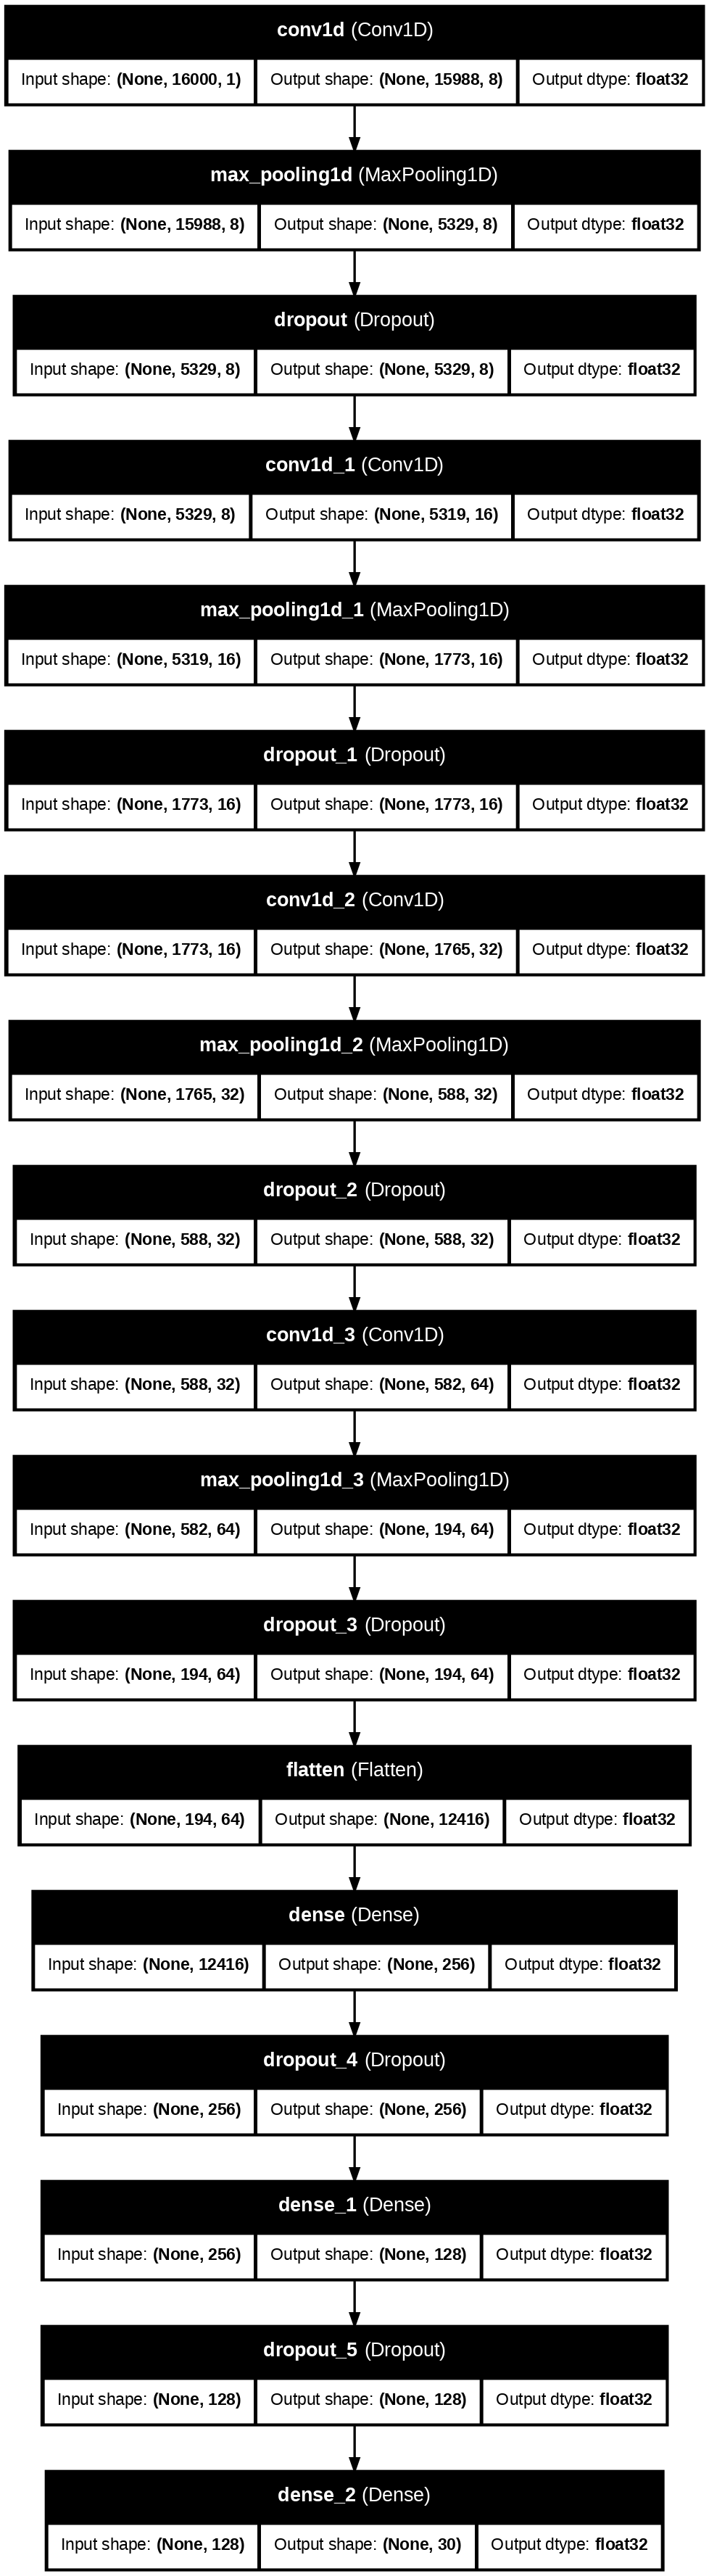

In [30]:
tf.keras.utils.plot_model(model, to_file='model.png', show_shapes=True, show_layer_names=True,show_dtype=True,dpi=120)

In [31]:
y_train[:100]

array([26,  8, 27, 14, 27, 12,  1,  8, 21,  9, 19, 26, 25, 19, 22, 24, 28,
       29, 27,  6, 20, 10,  7,  8,  5,  8,  3, 19,  7, 28,  7, 16, 15, 14,
       24,  5, 14, 25,  6, 23, 18, 26, 13, 16, 27, 21, 10,  6, 25, 16, 10,
       19, 11, 21, 28, 22, 19, 16, 24, 16,  9, 10, 25, 10, 25,  2, 10,  4,
       26, 18, 16,  3, 11, 20, 27,  5,  2, 22, 14, 25, 11, 19, 15,  0,  7,
        5,  6,  7, 22,  4,  7,  2, 28, 19,  3,  4, 23,  6, 17, 28])

In [32]:
model.compile(optimizer ='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
hist=model.fit(X_train,y_train,epochs=30)

Epoch 1/30
1177/1177 ━━━━━━━━━━━━━━━━━━━━ 85s 66ms/step - accuracy: 0.1719 - loss: 2.8044
Epoch 2/30
1177/1177 ━━━━━━━━━━━━━━━━━━━━ 78s 66ms/step - accuracy: 0.6032 - loss: 1.2263
Epoch 3/30
1177/1177 ━━━━━━━━━━━━━━━━━━━━ 78s 66ms/step - accuracy: 0.7514 - loss: 0.7430
Epoch 4/30
1177/1177 ━━━━━━━━━━━━━━━━━━━━ 77s 66ms/step - accuracy: 0.8076 - loss: 0.5737
Epoch 5/30
1177/1177 ━━━━━━━━━━━━━━━━━━━━ 77s 66ms/step - accuracy: 0.8477 - loss: 0.4621
Epoch 6/30
1177/1177 ━━━━━━━━━━━━━━━━━━━━ 77s 66ms/step - accuracy: 0.8713 - loss: 0.3839
Epoch 7/30
1177/1177 ━━━━━━━━━━━━━━━━━━━━ 77s 66ms/step - accuracy: 0.8763 - loss: 0.3630
Epoch 8/30
1177/1177 ━━━━━━━━━━━━━━━━━━━━ 78s 66ms/step - accuracy: 0.8956 - loss: 0.3164
Epoch 10/30
1177/1177 ━━━━━━━━━━━━━━━━━━━━ 78s 66ms/step - accuracy: 0.9090 - loss: 0.2860
Epoch 11/30
1177/1177 ━━━━━━━━━━━━━━━━━━━━ 78s 66ms/step - accuracy: 0.9078 - loss: 0.2833
Epoch 12/30
1177/1177 ━━━━━━━━━━━━━━━━━━━━ 78s 66ms/step - accuracy: 0.9205 - loss: 0.2436
Epoch 1

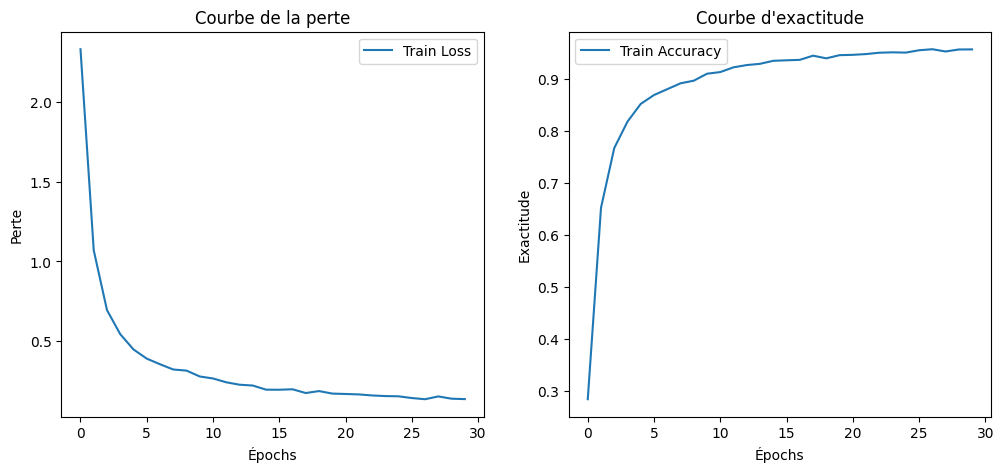

In [36]:

# Affichage de la courbe d'apprentissage
plt.figure(figsize=(12, 5))

# Courbe de la perte (loss)
plt.subplot(1, 2, 1)
plt.plot(hist.history['loss'], label='Train Loss')
plt.xlabel('Épochs')
plt.ylabel('Perte')
plt.title('Courbe de la perte')
plt.legend()

# Courbe de l'exactitude (accuracy)
plt.subplot(1, 2, 2)
plt.plot(hist.history['accuracy'], label='Train Accuracy')
plt.xlabel('Épochs')
plt.ylabel('Exactitude')
plt.title('Courbe d\'exactitude')
plt.legend()

plt.show()


In [38]:
loss,acc=model.evaluate(X_test,y_test)
print('Loss is :',loss)
print('ACC is :',acc)

131/131 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9666 - loss: 0.0959
Loss is : 0.09620480984449387
ACC is : 0.9667861461639404


In [37]:
predict=model.predict(X_test)

131/131 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step


In [40]:

# Inverser le dictionnaire lbl 
lbl_inv = {v: k for k, v in lbl.items()}

# Prédire les classes
predict = model.predict(X_test)
y_pred_classes = np.argmax(predict, axis=1)

# Afficher les résultats avec labels réels
for i in range(10):  
    vrai_label = lbl_inv[y_test[i]]
    pred_label = lbl_inv[y_pred_classes[i]]
    print(f"Prédiction : {pred_label}  |  Vérité : {vrai_label}")


131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Prédiction : off  |  Vérité : off
Prédiction : down  |  Vérité : down
Prédiction : marvel  |  Vérité : marvel
Prédiction : happy  |  Vérité : happy
Prédiction : happy  |  Vérité : happy
Prédiction : zero  |  Vérité : zero
Prédiction : on  |  Vérité : on
Prédiction : dog  |  Vérité : dog
Prédiction : house  |  Vérité : house
Prédiction : zero  |  Vérité : zero


In [41]:
class_names = list(lbl_inv.values())  # Liste des noms des classes


In [43]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Afficher le rapport de classification
print(classification_report(y_test, y_pred_classes, target_names=class_names))


              precision    recall  f1-score   support

          no       0.96      0.99      0.97        91
         two       1.00      0.90      0.95        91
        four       0.98      0.98      0.98       201
        five       0.99      0.99      0.99       102
        nine       0.96      0.98      0.97       116
       right       0.96      0.98      0.97       114
         off       0.96      0.99      0.97       241
         yes       1.00      0.94      0.97       140
         six       1.00      1.00      1.00       150
         dog       0.97      0.98      0.97       174
        left       0.94      0.98      0.96       148
        bird       0.96      0.96      0.96       105
      marvel       1.00      0.95      0.98       148
         wow       1.00      0.96      0.98        92
        zero       0.99      0.98      0.99       142
       eight       0.95      0.93      0.94       112
         bed       0.91      0.99      0.95       125
          go       0.96    

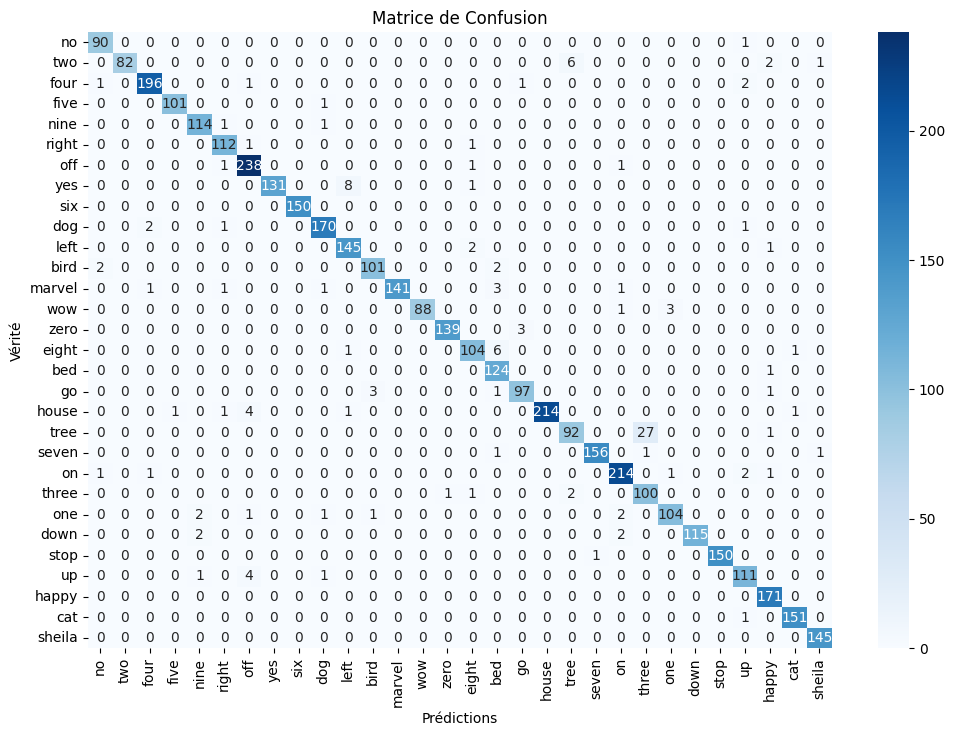

In [44]:
# Calculer la matrice de confusion
conf_matrix = confusion_matrix(y_test, y_pred_classes)

# Afficher la matrice sous forme de heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Prédictions")
plt.ylabel("Vérité")
plt.title("Matrice de Confusion")
plt.show()


In [46]:
model.save('/kaggle/working/speech_recognation_model.keras')
